In [1]:
# ============================================================
# STAGE 5 - CELL 1: Import Libraries and Load All Data
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib
import warnings
warnings.filterwarnings('ignore')

# XGBoost — the gradient boosting library
import xgboost as xgb

# TensorFlow — to load the trained CNN-biLSTM models
import tensorflow as tf
from tensorflow.keras.models import load_model

# Scikit-learn metrics
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# Set random seed for reproducibility
np.random.seed(42)

# Plot styling
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size']      = 11
plt.rcParams['axes.grid']      = True
plt.rcParams['grid.alpha']     = 0.3
sns.set_theme(style="whitegrid")

# ── Paths ─────────────────────────────────────────────────────
PROJECT_ROOT = "C:/Users/Mahir/Desktop/Solar_Energy_Forecasting_Project"
RESULTS_DIR  = os.path.join(PROJECT_ROOT, "results")
MODELS_DIR   = os.path.join(PROJECT_ROOT, "models")
PLOTS_DIR    = os.path.join(PROJECT_ROOT, "plots")
SEQ_DIR      = os.path.join(RESULTS_DIR, "sequences")

# ── Load sequence arrays ───────────────────────────────────────
print("Loading sequences...")

# Kano
X_train_kano  = np.load(os.path.join(SEQ_DIR,'X_train_kano.npy'))
y_train_kano  = np.load(os.path.join(SEQ_DIR,'y_train_kano.npy'))
X_val_kano    = np.load(os.path.join(SEQ_DIR,'X_val_kano.npy'))
y_val_kano    = np.load(os.path.join(SEQ_DIR,'y_val_kano.npy'))
X_test_kano   = np.load(os.path.join(SEQ_DIR,'X_test_kano.npy'))
y_test_kano   = np.load(os.path.join(SEQ_DIR,'y_test_kano.npy'))

# Maiduguri
X_train_maid  = np.load(os.path.join(SEQ_DIR,'X_train_maid.npy'))
y_train_maid  = np.load(os.path.join(SEQ_DIR,'y_train_maid.npy'))
X_val_maid    = np.load(os.path.join(SEQ_DIR,'X_val_maid.npy'))
y_val_maid    = np.load(os.path.join(SEQ_DIR,'y_val_maid.npy'))
X_test_maid   = np.load(os.path.join(SEQ_DIR,'X_test_maid.npy'))
y_test_maid   = np.load(os.path.join(SEQ_DIR,'y_test_maid.npy'))

# Abuja
X_train_abuja = np.load(os.path.join(SEQ_DIR,'X_train_abuja.npy'))
y_train_abuja = np.load(os.path.join(SEQ_DIR,'y_train_abuja.npy'))
X_val_abuja   = np.load(os.path.join(SEQ_DIR,'X_val_abuja.npy'))
y_val_abuja   = np.load(os.path.join(SEQ_DIR,'y_val_abuja.npy'))
X_test_abuja  = np.load(os.path.join(SEQ_DIR,'X_test_abuja.npy'))
y_test_abuja  = np.load(os.path.join(SEQ_DIR,'y_test_abuja.npy'))

# ── Load CNN-biLSTM predictions from Stage 4 ──────────────────
print("Loading Stage 4 CNN-biLSTM predictions...")

y_true_kano  = np.load(
    os.path.join(RESULTS_DIR,'y_true_kano.npy'))
y_true_maid  = np.load(
    os.path.join(RESULTS_DIR,'y_true_maid.npy'))
y_true_abuja = np.load(
    os.path.join(RESULTS_DIR,'y_true_abuja.npy'))

y_pred_cnn_kano  = np.load(
    os.path.join(RESULTS_DIR,'y_pred_cnn_kano.npy'))
y_pred_cnn_maid  = np.load(
    os.path.join(RESULTS_DIR,'y_pred_cnn_maid.npy'))
y_pred_cnn_abuja = np.load(
    os.path.join(RESULTS_DIR,'y_pred_cnn_abuja.npy'))

y_train_pred_kano  = np.load(
    os.path.join(RESULTS_DIR,'y_train_pred_cnn_kano.npy'))
y_train_pred_maid  = np.load(
    os.path.join(RESULTS_DIR,'y_train_pred_cnn_maid.npy'))
y_train_pred_abuja = np.load(
    os.path.join(RESULTS_DIR,'y_train_pred_cnn_abuja.npy'))

# ── Load target scalers ────────────────────────────────────────
tgt_scaler_kano  = joblib.load(
    os.path.join(MODELS_DIR,'tgt_scaler_kano.pkl'))
tgt_scaler_maid  = joblib.load(
    os.path.join(MODELS_DIR,'tgt_scaler_maid.pkl'))
tgt_scaler_abuja = joblib.load(
    os.path.join(MODELS_DIR,'tgt_scaler_abuja.pkl'))

# ── Load CNN-biLSTM models ─────────────────────────────────────
print("Loading trained CNN-biLSTM models...")

model_kano  = load_model(os.path.join(
    MODELS_DIR,'best_cnn_bilstm_kano.keras'))
model_maid  = load_model(os.path.join(
    MODELS_DIR,'best_cnn_bilstm_maiduguri.keras'))
model_abuja = load_model(os.path.join(
    MODELS_DIR,'best_cnn_bilstm_abuja.keras'))

print("\n" + "="*55)
print("ALL DATA AND MODELS LOADED SUCCESSFULLY")
print("="*55)
print(f"\nKano  true values : {len(y_true_kano):,}")
print(f"Kano  CNN preds   : {len(y_pred_cnn_kano):,}")
print(f"Kano  train preds : {len(y_train_pred_kano):,}")

Loading sequences...
Loading Stage 4 CNN-biLSTM predictions...
Loading trained CNN-biLSTM models...

ALL DATA AND MODELS LOADED SUCCESSFULLY

Kano  true values : 8,736
Kano  CNN preds   : 8,736
Kano  train preds : 52,560


RESIDUAL ANALYSIS — CNN-biLSTM ERRORS


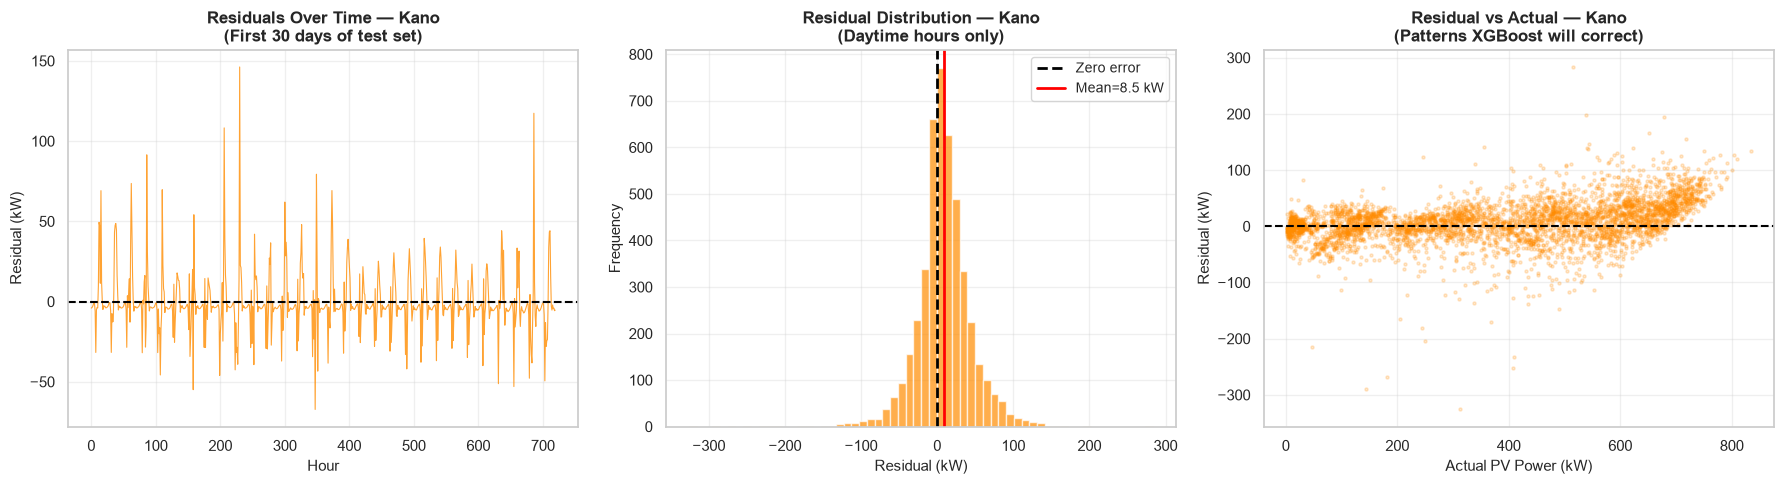


─────────────────────────────────────────────
RESIDUAL STATISTICS — KANO
─────────────────────────────────────────────
  Mean residual  : 8.4990 kW
  Std residual   : 36.1784 kW
  Max over-pred  : -325.9806 kW
  Max under-pred : 283.5069 kW
  % hours within ±50 kW: 86.1%


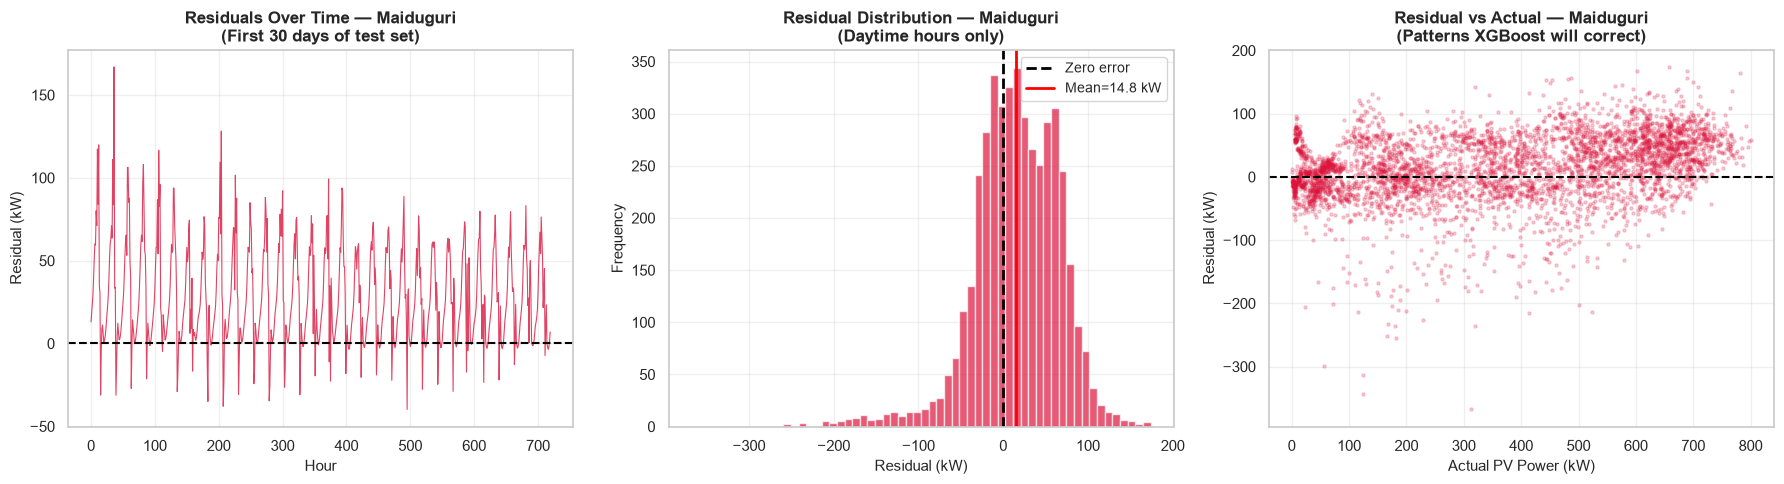


─────────────────────────────────────────────
RESIDUAL STATISTICS — MAIDUGURI
─────────────────────────────────────────────
  Mean residual  : 14.7525 kW
  Std residual   : 52.1199 kW
  Max over-pred  : -367.8125 kW
  Max under-pred : 173.8855 kW
  % hours within ±50 kW: 65.9%


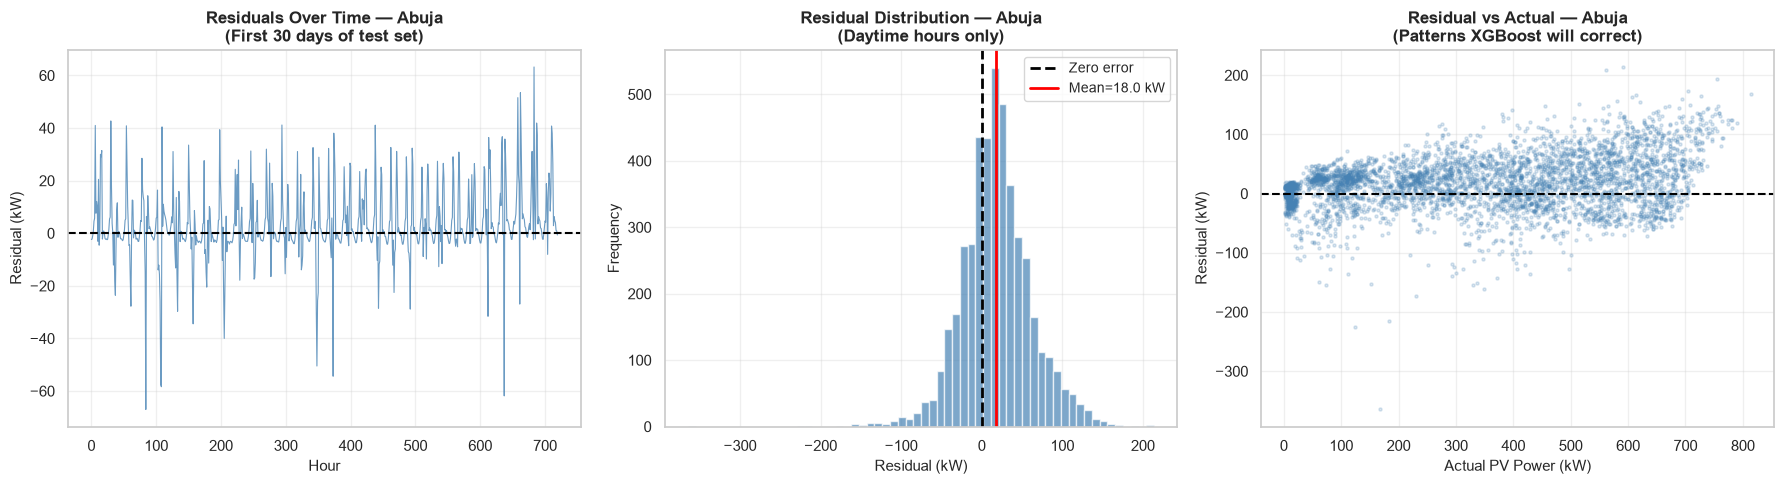


─────────────────────────────────────────────
RESIDUAL STATISTICS — ABUJA
─────────────────────────────────────────────
  Mean residual  : 18.0087 kW
  Std residual   : 43.6921 kW
  Max over-pred  : -364.6055 kW
  Max under-pred : 213.8335 kW
  % hours within ±50 kW: 75.4%


In [2]:
# ============================================================
# STAGE 5 - CELL 2: Analyse CNN-biLSTM Residual Errors
# ============================================================

# A residual is simply the difference between what the
# CNN-biLSTM predicted and what actually happened:
#
#   Residual = Actual - Predicted
#
# Positive residual: model under-predicted (actual was higher)
# Negative residual: model over-predicted (actual was lower)
#
# XGBoost will learn to predict these residuals so we can
# add the correction to the CNN-biLSTM prediction

def analyse_residuals(y_true, y_pred_cnn, city_name, color):
    """
    Computes and visualises the residual errors
    from the CNN-biLSTM predictions.
    """

    # Compute residuals
    residuals = y_true - y_pred_cnn

    # Daytime only for meaningful analysis
    mask       = y_true > 0
    res_day    = residuals[mask]

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # ── Plot 1: Residual Time Series ──────────────────────────
    axes[0].plot(residuals[:24*30],  # First 30 days
                 color=color,
                 linewidth=0.8, alpha=0.8)
    axes[0].axhline(y=0, color='black',
                    linewidth=1.5, linestyle='--')
    axes[0].set_title(f'Residuals Over Time — {city_name}\n'
                       f'(First 30 days of test set)',
                       fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Hour', fontsize=11)
    axes[0].set_ylabel('Residual (kW)', fontsize=11)

    # ── Plot 2: Residual Distribution ─────────────────────────
    axes[1].hist(res_day, bins=60,
                 color=color, alpha=0.7,
                 edgecolor='white')
    axes[1].axvline(x=0, color='black',
                    linewidth=2, linestyle='--',
                    label='Zero error')
    axes[1].axvline(x=res_day.mean(),
                    color='red', linewidth=2,
                    linestyle='-',
                    label=f'Mean={res_day.mean():.1f} kW')
    axes[1].set_title(f'Residual Distribution — {city_name}\n'
                       f'(Daytime hours only)',
                       fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Residual (kW)', fontsize=11)
    axes[1].set_ylabel('Frequency', fontsize=11)
    axes[1].legend(fontsize=10)

    # ── Plot 3: Residual vs Actual (scatter) ──────────────────
    axes[2].scatter(y_true[mask], res_day,
                    alpha=0.2, s=5, color=color)
    axes[2].axhline(y=0, color='black',
                    linewidth=1.5, linestyle='--')
    axes[2].set_title(f'Residual vs Actual — {city_name}\n'
                       f'(Patterns XGBoost will correct)',
                       fontsize=12, fontweight='bold')
    axes[2].set_xlabel('Actual PV Power (kW)', fontsize=11)
    axes[2].set_ylabel('Residual (kW)', fontsize=11)

    plt.tight_layout()
    save_path = os.path.join(
        PLOTS_DIR,
        f'Residuals_{city_name.lower()}.png')
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

    # Print residual statistics
    print(f"\n{'─'*45}")
    print(f"RESIDUAL STATISTICS — {city_name.upper()}")
    print(f"{'─'*45}")
    print(f"  Mean residual  : {res_day.mean():.4f} kW")
    print(f"  Std residual   : {res_day.std():.4f} kW")
    print(f"  Max over-pred  : {res_day.min():.4f} kW")
    print(f"  Max under-pred : {res_day.max():.4f} kW")
    print(f"  % hours within ±50 kW: "
          f"{(np.abs(res_day) < 50).mean()*100:.1f}%")

    return residuals


print("="*55)
print("RESIDUAL ANALYSIS — CNN-biLSTM ERRORS")
print("="*55)

res_kano  = analyse_residuals(
    y_true_kano,  y_pred_cnn_kano,  'Kano',      'darkorange')
res_maid  = analyse_residuals(
    y_true_maid,  y_pred_cnn_maid,  'Maiduguri', 'crimson')
res_abuja = analyse_residuals(
    y_true_abuja, y_pred_cnn_abuja, 'Abuja',     'steelblue')

In [3]:
# ============================================================
# STAGE 5 - CELL 3: Prepare XGBoost Meta-Features
# ============================================================

# XGBoost receives a special set of features called
# "meta-features" that combine:
# 1. The CNN-biLSTM's latent representation (last timestep
#    of each sequence — a compressed summary of the 24hr window)
# 2. The CNN-biLSTM's actual prediction value
# 3. Key raw features from the last hour of each sequence
#
# This gives XGBoost rich contextual information about
# both what the CNN-biLSTM saw and what it predicted,
# enabling it to identify systematic error patterns

def prepare_xgb_features(X_sequences,
                          cnn_predictions_norm,
                          city_name):
    """
    Creates the feature matrix for XGBoost training.

    Extracts the last timestep of each sequence
    (the most recent hour before the prediction)
    and combines it with the CNN-biLSTM's normalised prediction.

    Parameters:
        X_sequences        : 3D array (N, 24, 17)
        cnn_predictions_norm: 1D array of normalised predictions
        city_name          : string for display

    Returns:
        meta_features : 2D array (N, 18) for XGBoost input
    """

    # Extract the last timestep from each 24-hour sequence
    # This is the most recent hour's feature values
    # Shape: (N, 17) — one row of features per sequence
    last_timestep = X_sequences[:, -1, :]

    # Stack horizontally with the CNN prediction
    # Result shape: (N, 18) — 17 features + 1 prediction
    meta_features = np.hstack([
        last_timestep,                        # 17 features
        cnn_predictions_norm.reshape(-1, 1)   # CNN prediction
    ])

    print(f"  {city_name} meta-features shape: "
          f"{meta_features.shape}")
    print(f"  Columns: 17 last-timestep features "
          f"+ 1 CNN prediction = 18 total")

    return meta_features


print("="*55)
print("PREPARING XGBOOST META-FEATURES")
print("="*55)
print("\nTraining meta-features:")

# ── Training meta-features ────────────────────────────────────
# CNN training predictions are already in normalised scale
# (0 to 1) as saved in Stage 4
meta_train_kano  = prepare_xgb_features(
    X_train_kano, y_train_pred_kano,  'Kano Train')
meta_train_maid  = prepare_xgb_features(
    X_train_maid, y_train_pred_maid,  'Maiduguri Train')
meta_train_abuja = prepare_xgb_features(
    X_train_abuja, y_train_pred_abuja,'Abuja Train')

# ── Test meta-features ────────────────────────────────────────
# For test, we need normalised CNN predictions
# Convert back from kW to normalised scale
print("\nTest meta-features:")

cnn_test_norm_kano = tgt_scaler_kano.transform(
    y_pred_cnn_kano.reshape(-1,1)).flatten()
cnn_test_norm_maid = tgt_scaler_maid.transform(
    y_pred_cnn_maid.reshape(-1,1)).flatten()
cnn_test_norm_abuja = tgt_scaler_abuja.transform(
    y_pred_cnn_abuja.reshape(-1,1)).flatten()

meta_test_kano  = prepare_xgb_features(
    X_test_kano,  cnn_test_norm_kano,  'Kano Test')
meta_test_maid  = prepare_xgb_features(
    X_test_maid,  cnn_test_norm_maid,  'Maiduguri Test')
meta_test_abuja = prepare_xgb_features(
    X_test_abuja, cnn_test_norm_abuja, 'Abuja Test')

# ── Training residuals (what XGBoost learns to predict) ───────
# Compute training residuals in normalised scale
# because CNN predictions are in normalised scale

# Convert training true values back from normalised
y_train_true_kw_kano = tgt_scaler_kano.inverse_transform(
    y_train_kano.reshape(-1,1)).flatten()
y_train_true_kw_maid = tgt_scaler_maid.inverse_transform(
    y_train_maid.reshape(-1,1)).flatten()
y_train_true_kw_abuja = tgt_scaler_abuja.inverse_transform(
    y_train_abuja.reshape(-1,1)).flatten()

# Convert CNN training predictions from normalised to kW
y_train_pred_kw_kano = tgt_scaler_kano.inverse_transform(
    y_train_pred_kano.reshape(-1,1)).flatten()
y_train_pred_kw_maid = tgt_scaler_maid.inverse_transform(
    y_train_pred_maid.reshape(-1,1)).flatten()
y_train_pred_kw_abuja = tgt_scaler_abuja.inverse_transform(
    y_train_pred_abuja.reshape(-1,1)).flatten()

# Training residuals in kW
residuals_train_kano  = (y_train_true_kw_kano
                          - y_train_pred_kw_kano)
residuals_train_maid  = (y_train_true_kw_maid
                          - y_train_pred_kw_maid)
residuals_train_abuja = (y_train_true_kw_abuja
                          - y_train_pred_kw_abuja)

print("\n" + "="*55)
print("TRAINING RESIDUAL STATISTICS")
print("="*55)
for name, res in [('Kano',      residuals_train_kano),
                   ('Maiduguri', residuals_train_maid),
                   ('Abuja',     residuals_train_abuja)]:
    print(f"\n{name}:")
    print(f"  Mean : {res.mean():.4f} kW")
    print(f"  Std  : {res.std():.4f} kW")
    print(f"  Range: {res.min():.2f} to {res.max():.2f} kW")

PREPARING XGBOOST META-FEATURES

Training meta-features:
  Kano Train meta-features shape: (52560, 18)
  Columns: 17 last-timestep features + 1 CNN prediction = 18 total
  Maiduguri Train meta-features shape: (52560, 18)
  Columns: 17 last-timestep features + 1 CNN prediction = 18 total
  Abuja Train meta-features shape: (52560, 18)
  Columns: 17 last-timestep features + 1 CNN prediction = 18 total

Test meta-features:
  Kano Test meta-features shape: (8736, 18)
  Columns: 17 last-timestep features + 1 CNN prediction = 18 total
  Maiduguri Test meta-features shape: (8736, 18)
  Columns: 17 last-timestep features + 1 CNN prediction = 18 total
  Abuja Test meta-features shape: (8736, 18)
  Columns: 17 last-timestep features + 1 CNN prediction = 18 total

TRAINING RESIDUAL STATISTICS

Kano:
  Mean : 5.6373 kW
  Std  : 27.3679 kW
  Range: -468.48 to 325.57 kW

Maiduguri:
  Mean : 12.1519 kW
  Std  : 40.4948 kW
  Range: -452.39 to 338.60 kW

Abuja:
  Mean : 11.0391 kW
  Std  : 32.6875 kW
  

In [4]:
# ============================================================
# STAGE 5 - CELL 4: Train XGBoost Residual Correctors
# ============================================================

# XGBoost will learn to predict the residual errors
# made by the CNN-biLSTM on the training data.
#
# Once trained, when given a new prediction scenario:
# 1. CNN-biLSTM makes prediction P
# 2. XGBoost predicts the expected residual R
# 3. Final prediction = P + R
#
# XGBoost hyperparameters:
# n_estimators  : number of trees to build (300)
# max_depth     : how deep each tree can grow (4)
#   Deeper trees learn more complex patterns but risk overfitting
# learning_rate : step size for each tree addition (0.05)
#   Small learning rate + many trees = better generalisation
# subsample     : fraction of training data per tree (0.8)
#   Using 80% of data per tree adds beneficial randomness
# colsample     : fraction of features per tree split (0.8)
#   Using 80% of features adds more randomness
# min_child_weight: minimum samples in a leaf node (5)
#   Higher value prevents learning from tiny sample groups
# reg_alpha/lambda: L1 and L2 regularisation
#   Prevents overfitting by penalising complex trees

XGB_PARAMS = {
    'n_estimators'      : 300,
    'max_depth'         : 4,
    'learning_rate'     : 0.05,
    'subsample'         : 0.8,
    'colsample_bytree'  : 0.8,
    'min_child_weight'  : 5,
    'reg_alpha'         : 0.1,
    'reg_lambda'        : 1.0,
    'objective'         : 'reg:squarederror',
    'random_state'      : 42,
    'n_jobs'            : -1,    # Use all CPU cores
    'verbosity'         : 0
}


def train_xgboost(meta_train, residuals_train,
                   meta_test, city_name):
    """
    Trains an XGBoost model to predict CNN-biLSTM residuals.

    Parameters:
        meta_train      : 2D training meta-features (N_train, 18)
        residuals_train : 1D training residuals in kW (N_train,)
        meta_test       : 2D test meta-features (N_test, 18)
        city_name       : string for display

    Returns:
        xgb_model           : trained XGBoost model
        residual_pred_train : predicted residuals on training data
        residual_pred_test  : predicted residuals on test data
    """

    print(f"\n{'─'*45}")
    print(f"Training XGBoost — {city_name}")
    print(f"{'─'*45}")
    print(f"  Training samples: {len(meta_train):,}")
    print(f"  Feature count   : {meta_train.shape[1]}")
    print(f"  Target range    : {residuals_train.min():.1f} "
          f"to {residuals_train.max():.1f} kW")

    # Initialise and train XGBoost
    xgb_model = xgb.XGBRegressor(**XGB_PARAMS)
    xgb_model.fit(meta_train, residuals_train)

    # Generate residual predictions
    residual_pred_train = xgb_model.predict(meta_train)
    residual_pred_test  = xgb_model.predict(meta_test)

    print(f"  Training complete ✅")
    print(f"  Predicted residual range (test): "
          f"{residual_pred_test.min():.2f} to "
          f"{residual_pred_test.max():.2f} kW")

    return xgb_model, residual_pred_train, residual_pred_test


print("="*55)
print("XGBOOST RESIDUAL CORRECTOR TRAINING")
print("="*55)

# Train for all three cities
(xgb_kano, xgb_res_train_kano,
 xgb_res_test_kano)  = train_xgboost(
    meta_train_kano,  residuals_train_kano,
    meta_test_kano,   'Kano')

(xgb_maid, xgb_res_train_maid,
 xgb_res_test_maid)  = train_xgboost(
    meta_train_maid,  residuals_train_maid,
    meta_test_maid,   'Maiduguri')

(xgb_abuja, xgb_res_train_abuja,
 xgb_res_test_abuja) = train_xgboost(
    meta_train_abuja, residuals_train_abuja,
    meta_test_abuja,  'Abuja')

# Save XGBoost models
joblib.dump(xgb_kano,
    os.path.join(MODELS_DIR, 'xgb_kano.pkl'))
joblib.dump(xgb_maid,
    os.path.join(MODELS_DIR, 'xgb_maid.pkl'))
joblib.dump(xgb_abuja,
    os.path.join(MODELS_DIR, 'xgb_abuja.pkl'))

print("\n" + "="*55)
print("ALL XGBOOST MODELS TRAINED AND SAVED")
print("="*55)
print("✅ xgb_kano.pkl")
print("✅ xgb_maid.pkl")
print("✅ xgb_abuja.pkl")

XGBOOST RESIDUAL CORRECTOR TRAINING

─────────────────────────────────────────────
Training XGBoost — Kano
─────────────────────────────────────────────
  Training samples: 52,560
  Feature count   : 18
  Target range    : -468.5 to 325.6 kW
  Training complete ✅
  Predicted residual range (test): -45.18 to 116.26 kW

─────────────────────────────────────────────
Training XGBoost — Maiduguri
─────────────────────────────────────────────
  Training samples: 52,560
  Feature count   : 18
  Target range    : -452.4 to 338.6 kW
  Training complete ✅
  Predicted residual range (test): -125.25 to 176.84 kW

─────────────────────────────────────────────
Training XGBoost — Abuja
─────────────────────────────────────────────
  Training samples: 52,560
  Feature count   : 18
  Target range    : -356.3 to 305.0 kW
  Training complete ✅
  Predicted residual range (test): -67.79 to 122.62 kW

ALL XGBOOST MODELS TRAINED AND SAVED
✅ xgb_kano.pkl
✅ xgb_maid.pkl
✅ xgb_abuja.pkl


In [5]:
# ============================================================
# STAGE 5 - CELL 5: Generate Final Hybrid Predictions
# ============================================================

# The final hybrid prediction combines:
# CNN-biLSTM prediction + XGBoost residual correction
#
# This is the complete CNN-biLSTM + XGBoost pipeline output

def generate_hybrid_predictions(y_pred_cnn,
                                  xgb_residual_pred,
                                  y_true,
                                  city_name):
    """
    Combines CNN-biLSTM predictions with XGBoost residual
    corrections to produce the final hybrid predictions.

    Also clips negative values to zero since PV power
    cannot be negative — this also fixes the negative
    prediction issue you noticed in Maiduguri.
    """

    # Add XGBoost residual correction
    y_pred_hybrid = y_pred_cnn + xgb_residual_pred

    # Clip negative predictions to zero
    # Physical constraint: power cannot be negative
    y_pred_hybrid = np.clip(y_pred_hybrid, 0, None)

    print(f"\n{city_name}:")
    print(f"  CNN-biLSTM pred range  : "
          f"{y_pred_cnn.min():.1f} to "
          f"{y_pred_cnn.max():.1f} kW")
    print(f"  XGBoost correction range: "
          f"{xgb_residual_pred.min():.1f} to "
          f"{xgb_residual_pred.max():.1f} kW")
    print(f"  Hybrid pred range      : "
          f"{y_pred_hybrid.min():.1f} to "
          f"{y_pred_hybrid.max():.1f} kW")
    print(f"  Actual range           : "
          f"{y_true.min():.1f} to "
          f"{y_true.max():.1f} kW")

    return y_pred_hybrid


print("="*55)
print("GENERATING FINAL HYBRID PREDICTIONS")
print("="*55)

y_pred_hybrid_kano  = generate_hybrid_predictions(
    y_pred_cnn_kano,  xgb_res_test_kano,
    y_true_kano,      'Kano')

y_pred_hybrid_maid  = generate_hybrid_predictions(
    y_pred_cnn_maid,  xgb_res_test_maid,
    y_true_maid,      'Maiduguri')

y_pred_hybrid_abuja = generate_hybrid_predictions(
    y_pred_cnn_abuja, xgb_res_test_abuja,
    y_true_abuja,     'Abuja')

GENERATING FINAL HYBRID PREDICTIONS

Kano:
  CNN-biLSTM pred range  : -51.2 to 719.4 kW
  XGBoost correction range: -45.2 to 116.3 kW
  Hybrid pred range      : 0.0 to 816.6 kW
  Actual range           : 0.0 to 834.1 kW

Maiduguri:
  CNN-biLSTM pred range  : -88.9 to 775.0 kW
  XGBoost correction range: -125.2 to 176.8 kW
  Hybrid pred range      : 0.0 to 811.1 kW
  Actual range           : 0.0 to 800.7 kW

Abuja:
  CNN-biLSTM pred range  : -19.7 to 734.2 kW
  XGBoost correction range: -67.8 to 122.6 kW
  Hybrid pred range      : 0.0 to 774.4 kW
  Actual range           : 0.0 to 813.7 kW


In [6]:
# ============================================================
# STAGE 5 - CELL 6: Performance Comparison
# ============================================================

def compute_metrics_full(y_true, y_pred, model_name, city):
    """Computes all metrics on daytime hours only."""

    mask       = y_true > 0
    y_true_day = y_true[mask]
    y_pred_day = y_pred[mask]

    rmse  = np.sqrt(mean_squared_error(y_true_day, y_pred_day))
    mae   = mean_absolute_error(y_true_day, y_pred_day)
    r2    = r2_score(y_true_day, y_pred_day)
    mape  = np.mean(np.abs(
        (y_true_day - y_pred_day) /
        (y_true_day + 1e-8))) * 100
    nrmse = (rmse / y_true_day.mean()) * 100

    return {
        'Model': model_name, 'City': city,
        'RMSE': round(rmse, 4),
        'MAE' : round(mae,  4),
        'R2'  : round(r2,   6),
        'MAPE': round(mape, 2),
        'nRMSE': round(nrmse, 2)
    }


print("="*60)
print("PERFORMANCE COMPARISON — CNN-biLSTM vs HYBRID")
print("="*60)

all_metrics = []

cities_data = [
    ('Kano',      y_true_kano,
     y_pred_cnn_kano,  y_pred_hybrid_kano),
    ('Maiduguri', y_true_maid,
     y_pred_cnn_maid,  y_pred_hybrid_maid),
    ('Abuja',     y_true_abuja,
     y_pred_cnn_abuja, y_pred_hybrid_abuja),
]

for city, y_true, y_cnn, y_hybrid in cities_data:

    m_cnn    = compute_metrics_full(
        y_true, y_cnn,    'CNN-biLSTM', city)
    m_hybrid = compute_metrics_full(
        y_true, y_hybrid, 'Hybrid',     city)

    all_metrics.extend([m_cnn, m_hybrid])

    # Show improvement
    rmse_imp = ((m_cnn['RMSE'] - m_hybrid['RMSE'])
                / m_cnn['RMSE'] * 100)
    r2_imp   = m_hybrid['R2'] - m_cnn['R2']

    print(f"\n{'─'*55}")
    print(f"{city.upper()}")
    print(f"{'─'*55}")
    print(f"{'Metric':<10} {'CNN-biLSTM':>14} "
          f"{'Hybrid':>14} {'Change':>12}")
    print(f"{'─'*55}")
    print(f"{'RMSE':<10} {m_cnn['RMSE']:>14.4f} "
          f"{m_hybrid['RMSE']:>14.4f} "
          f"{'↓'+str(round(rmse_imp,2))+'%':>12}")
    print(f"{'MAE':<10} {m_cnn['MAE']:>14.4f} "
          f"{m_hybrid['MAE']:>14.4f}")
    print(f"{'R²':<10} {m_cnn['R2']:>14.6f} "
          f"{m_hybrid['R2']:>14.6f} "
          f"{'↑'+str(round(r2_imp,4)):>12}")
    print(f"{'MAPE':<10} {m_cnn['MAPE']:>13.2f}% "
          f"{m_hybrid['MAPE']:>13.2f}%")
    print(f"{'nRMSE':<10} {m_cnn['nRMSE']:>13.2f}% "
          f"{m_hybrid['nRMSE']:>13.2f}%")

# Save full comparison table
metrics_df = pd.DataFrame(all_metrics)
metrics_df.to_csv(
    os.path.join(RESULTS_DIR, 'hybrid_vs_cnn_metrics.csv'),
    index=False)

print(f"\n\n{'='*60}")
print("FULL COMPARISON TABLE")
print(f"{'='*60}")
print(metrics_df.to_string(index=False))
print(f"\n✅ Comparison saved to hybrid_vs_cnn_metrics.csv")

PERFORMANCE COMPARISON — CNN-biLSTM vs HYBRID

───────────────────────────────────────────────────────
KANO
───────────────────────────────────────────────────────
Metric         CNN-biLSTM         Hybrid       Change
───────────────────────────────────────────────────────
RMSE              37.1633        30.5474       ↓17.8%
MAE               25.9985        17.9830
R²               0.975220       0.983258       ↑0.008
MAPE               18.79%         11.59%
nRMSE              10.16%          8.35%

───────────────────────────────────────────────────────
MAIDUGURI
───────────────────────────────────────────────────────
Metric         CNN-biLSTM         Hybrid       Change
───────────────────────────────────────────────────────
RMSE              54.1675        34.1141      ↓37.02%
MAE               41.4907        20.0698
R²               0.946654       0.978841      ↑0.0322
MAPE               46.29%         13.89%
nRMSE              14.98%          9.43%

──────────────────────────────

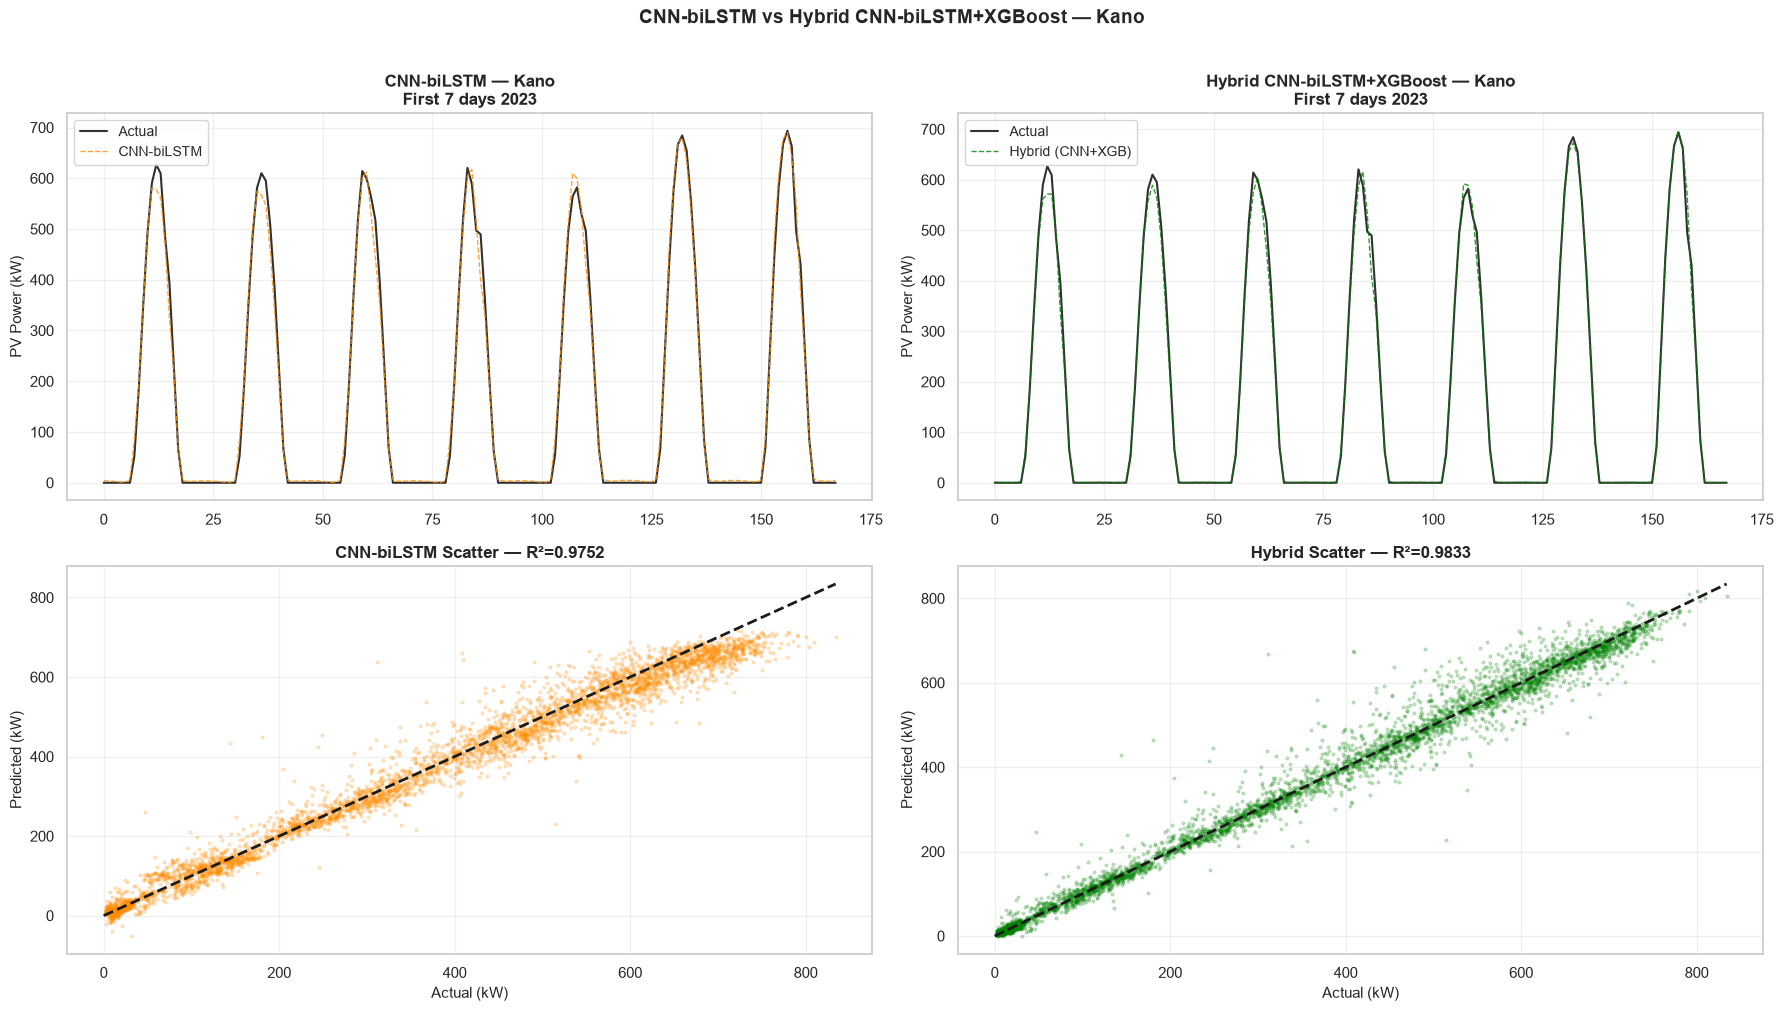

✅ Plot saved: C:/Users/Mahir/Desktop/Solar_Energy_Forecasting_Project\plots\Hybrid_comparison_kano.png


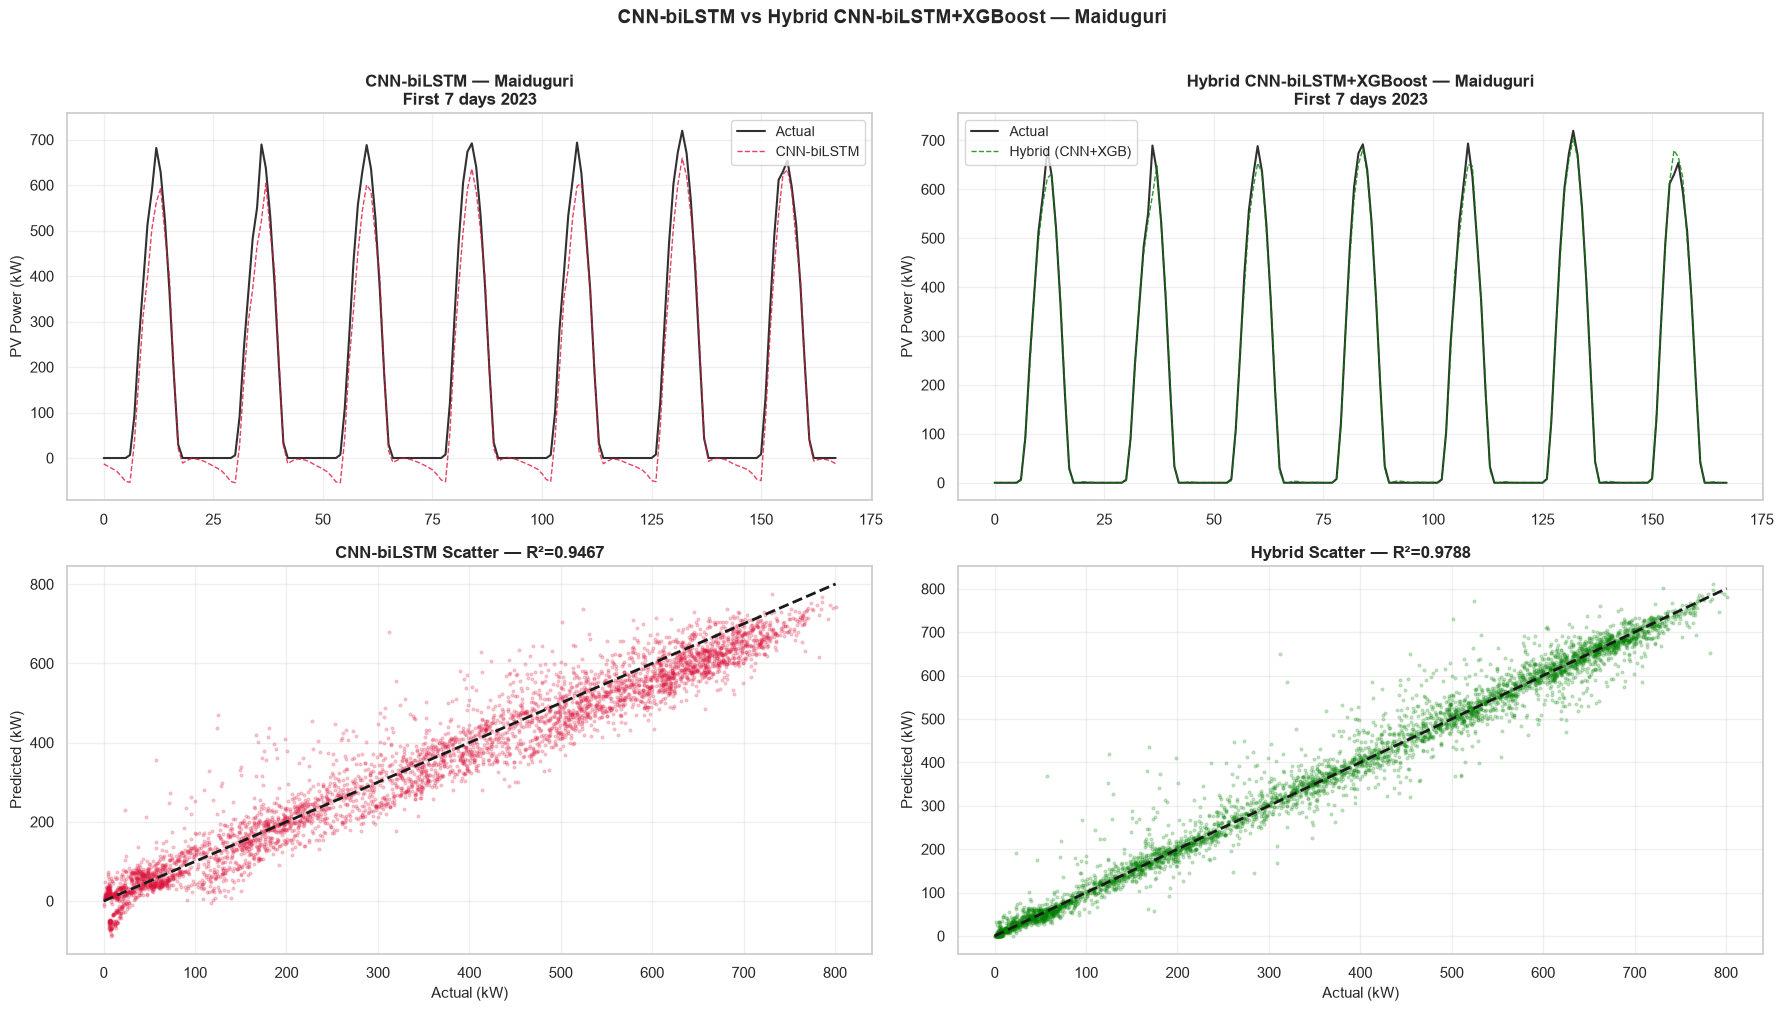

✅ Plot saved: C:/Users/Mahir/Desktop/Solar_Energy_Forecasting_Project\plots\Hybrid_comparison_maiduguri.png


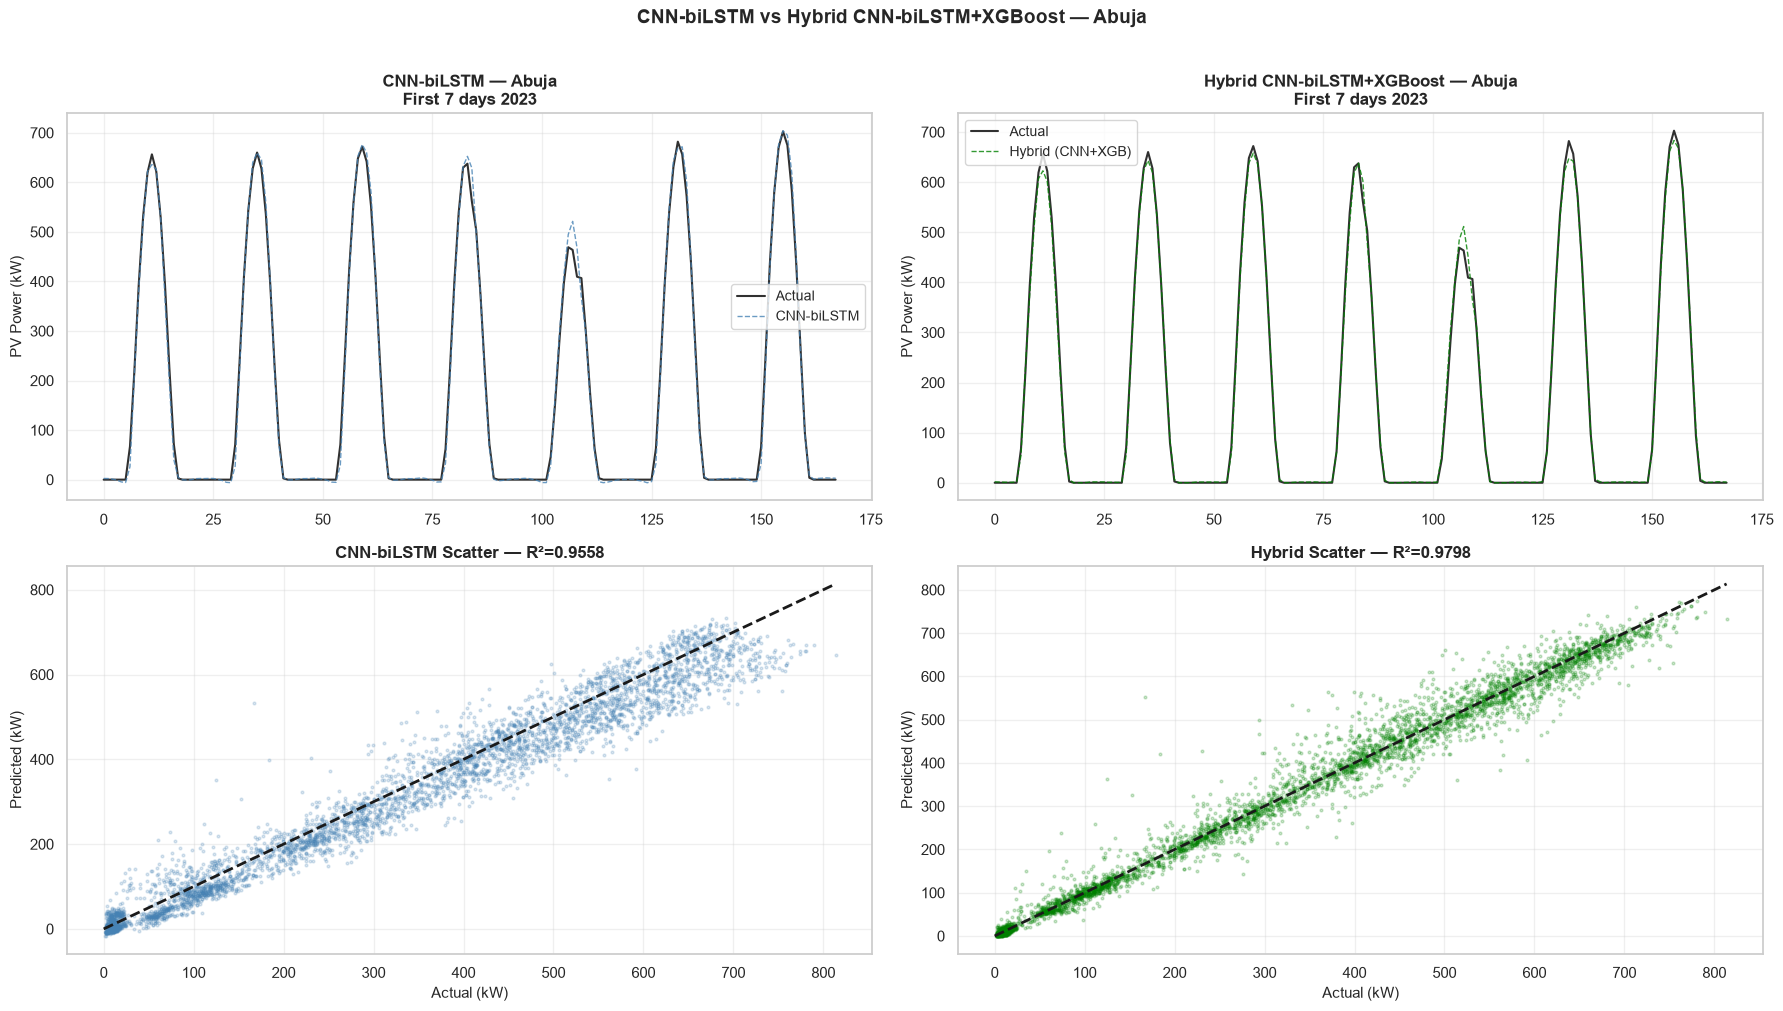

✅ Plot saved: C:/Users/Mahir/Desktop/Solar_Energy_Forecasting_Project\plots\Hybrid_comparison_abuja.png


In [7]:
# ============================================================
# STAGE 5 - CELL 7: Visual Comparison Plots
# ============================================================

def plot_hybrid_comparison(y_true, y_cnn,
                             y_hybrid, city_name,
                             color, n_days=7):
    """
    Creates side-by-side comparison of CNN-biLSTM
    and Hybrid predictions against actual values.
    """

    n_hours = n_days * 24

    fig, axes = plt.subplots(2, 2, figsize=(18, 10))

    # ── Top Left: CNN-biLSTM time series ──────────────────────
    axes[0,0].plot(range(n_hours),
                   y_true[:n_hours],
                   'k-', linewidth=1.5,
                   label='Actual', alpha=0.9)
    axes[0,0].plot(range(n_hours),
                   y_cnn[:n_hours],
                   color=color, linewidth=1,
                   linestyle='--',
                   label='CNN-biLSTM',
                   alpha=0.8)
    axes[0,0].set_title(f'CNN-biLSTM — {city_name}\n'
                         f'First {n_days} days 2023',
                         fontsize=12, fontweight='bold')
    axes[0,0].set_ylabel('PV Power (kW)', fontsize=11)
    axes[0,0].legend(fontsize=10)

    # ── Top Right: Hybrid time series ─────────────────────────
    axes[0,1].plot(range(n_hours),
                   y_true[:n_hours],
                   'k-', linewidth=1.5,
                   label='Actual', alpha=0.9)
    axes[0,1].plot(range(n_hours),
                   y_hybrid[:n_hours],
                   color='green', linewidth=1,
                   linestyle='--',
                   label='Hybrid (CNN+XGB)',
                   alpha=0.8)
    axes[0,1].set_title(f'Hybrid CNN-biLSTM+XGBoost — {city_name}\n'
                         f'First {n_days} days 2023',
                         fontsize=12, fontweight='bold')
    axes[0,1].set_ylabel('PV Power (kW)', fontsize=11)
    axes[0,1].legend(fontsize=10)

    # ── Bottom Left: CNN scatter ───────────────────────────────
    mask = y_true > 0
    r2_cnn = r2_score(y_true[mask], y_cnn[mask])
    axes[1,0].scatter(y_true[mask], y_cnn[mask],
                      alpha=0.2, s=4, color=color)
    max_val = y_true[mask].max()
    axes[1,0].plot([0, max_val], [0, max_val],
                   'k--', linewidth=2)
    axes[1,0].set_title(f'CNN-biLSTM Scatter — R²={r2_cnn:.4f}',
                         fontsize=12, fontweight='bold')
    axes[1,0].set_xlabel('Actual (kW)', fontsize=11)
    axes[1,0].set_ylabel('Predicted (kW)', fontsize=11)

    # ── Bottom Right: Hybrid scatter ──────────────────────────
    r2_hyb = r2_score(y_true[mask], y_hybrid[mask])
    axes[1,1].scatter(y_true[mask], y_hybrid[mask],
                      alpha=0.2, s=4, color='green')
    axes[1,1].plot([0, max_val], [0, max_val],
                   'k--', linewidth=2)
    axes[1,1].set_title(f'Hybrid Scatter — R²={r2_hyb:.4f}',
                         fontsize=12, fontweight='bold')
    axes[1,1].set_xlabel('Actual (kW)', fontsize=11)
    axes[1,1].set_ylabel('Predicted (kW)', fontsize=11)

    plt.suptitle(
        f'CNN-biLSTM vs Hybrid CNN-biLSTM+XGBoost — {city_name}',
        fontsize=14, fontweight='bold', y=1.01)
    plt.tight_layout()

    save_path = os.path.join(
        PLOTS_DIR,
        f'Hybrid_comparison_{city_name.lower()}.png')
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"✅ Plot saved: {save_path}")


# Plot all three cities
plot_hybrid_comparison(
    y_true_kano,  y_pred_cnn_kano,
    y_pred_hybrid_kano,  'Kano',      'darkorange')

plot_hybrid_comparison(
    y_true_maid,  y_pred_cnn_maid,
    y_pred_hybrid_maid,  'Maiduguri', 'crimson')

plot_hybrid_comparison(
    y_true_abuja, y_pred_cnn_abuja,
    y_pred_hybrid_abuja, 'Abuja',     'steelblue')

In [8]:
# ============================================================
# STAGE 5 - CELL 8: Save Final Hybrid Predictions
# ============================================================

# Save hybrid predictions for Stage 6 SHAP analysis
np.save(os.path.join(RESULTS_DIR,
                      'y_pred_hybrid_kano.npy'),
        y_pred_hybrid_kano)
np.save(os.path.join(RESULTS_DIR,
                      'y_pred_hybrid_maid.npy'),
        y_pred_hybrid_maid)
np.save(os.path.join(RESULTS_DIR,
                      'y_pred_hybrid_abuja.npy'),
        y_pred_hybrid_abuja)

# Also save XGBoost meta-features for SHAP analysis
np.save(os.path.join(RESULTS_DIR,
                      'meta_test_kano.npy'),
        meta_test_kano)
np.save(os.path.join(RESULTS_DIR,
                      'meta_test_maid.npy'),
        meta_test_maid)
np.save(os.path.join(RESULTS_DIR,
                      'meta_test_abuja.npy'),
        meta_test_abuja)

print("="*55)
print("HYBRID PREDICTIONS SAVED")
print("="*55)
print("✅ y_pred_hybrid_kano.npy")
print("✅ y_pred_hybrid_maid.npy")
print("✅ y_pred_hybrid_abuja.npy")
print("✅ meta_test_kano.npy  (for SHAP)")
print("✅ meta_test_maid.npy  (for SHAP)")
print("✅ meta_test_abuja.npy (for SHAP)")

HYBRID PREDICTIONS SAVED
✅ y_pred_hybrid_kano.npy
✅ y_pred_hybrid_maid.npy
✅ y_pred_hybrid_abuja.npy
✅ meta_test_kano.npy  (for SHAP)
✅ meta_test_maid.npy  (for SHAP)
✅ meta_test_abuja.npy (for SHAP)


In [9]:
# ============================================================
# STAGE 5 - CELL 9: Stage 5 Completion Summary
# ============================================================

print("="*60)
print("STAGE 5 COMPLETE — XGBOOST RESIDUAL CORRECTION")
print("="*60)
print()
print("✅ CNN-biLSTM residuals analysed")
print("   (Time series, distribution, vs actual plots)")
print()
print("✅ XGBoost meta-features prepared")
print("   (17 last-timestep features + 1 CNN prediction)")
print()
print("✅ XGBoost residual correctors trained")
print("   One model per city — 300 trees, max_depth=4")
print()
print("✅ Final hybrid predictions generated")
print("   Final = CNN-biLSTM prediction + XGBoost correction")
print("   Negative values clipped to zero")
print()
print("✅ Performance comparison completed:")
print()

# Final summary table
hybrid_metrics = metrics_df[
    metrics_df['Model']=='Hybrid']
cnn_metrics = metrics_df[
    metrics_df['Model']=='CNN-biLSTM']

print(f"  {'City':<12} {'CNN R²':>10} "
      f"{'Hybrid R²':>12} {'Improvement':>14}")
print(f"  {'─'*50}")
for city in ['Kano', 'Maiduguri', 'Abuja']:
    r2_cnn = cnn_metrics[
        cnn_metrics['City']==city]['R2'].values[0]
    r2_hyb = hybrid_metrics[
        hybrid_metrics['City']==city]['R2'].values[0]
    imp    = r2_hyb - r2_cnn
    print(f"  {city:<12} {r2_cnn:>10.6f} "
          f"{r2_hyb:>12.6f} "
          f"{'↑'+str(round(imp,4)):>14}")

print()
print("✅ All models saved:")
print("   xgb_kano.pkl, xgb_maid.pkl, xgb_abuja.pkl")
print()
print("✅ All predictions saved for Stage 6 SHAP analysis")
print()
print("NEXT → Stage 6: SHAP Explainability Analysis")
print("="*60)

STAGE 5 COMPLETE — XGBOOST RESIDUAL CORRECTION

✅ CNN-biLSTM residuals analysed
   (Time series, distribution, vs actual plots)

✅ XGBoost meta-features prepared
   (17 last-timestep features + 1 CNN prediction)

✅ XGBoost residual correctors trained
   One model per city — 300 trees, max_depth=4

✅ Final hybrid predictions generated
   Final = CNN-biLSTM prediction + XGBoost correction
   Negative values clipped to zero

✅ Performance comparison completed:

  City             CNN R²    Hybrid R²    Improvement
  ──────────────────────────────────────────────────
  Kano           0.975220     0.983258         ↑0.008
  Maiduguri      0.946654     0.978841        ↑0.0322
  Abuja          0.955765     0.979820        ↑0.0241

✅ All models saved:
   xgb_kano.pkl, xgb_maid.pkl, xgb_abuja.pkl

✅ All predictions saved for Stage 6 SHAP analysis

NEXT → Stage 6: SHAP Explainability Analysis
